# Degenerate spin systems: MaRs and EasySpin

Four spin systems with exactly degenerate levels (see `degenerate_examples.py`). For every system:


* the relative L2 difference of every spectrum from the best one (largest `N`, smallest `r_tol`) is tabulated;
* the finest MaRs spectrum is compared with EasySpin reference
  (`Opt.GridSize = [80 0]`, `Opt.ModellingAccuracy = 1e-7`, `Opt.Threshold = 1e-4`);

In [1]:
import warnings
import sys
import os

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import degenerate_examples as examples

warnings.filterwarnings("ignore", message="The degenerated")
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..", "..", "..", "..")))


MESHES = [20, 40, 60, 80]
TOLERANCES = [1e-3, 1e-4, 1e-5, 1e-7]
CASES = [(80, 1e-7)]
THRESHOLD = 1e-4


def l2_table(spectra):
    """Relative L2 difference of every spectrum from the best one (largest N, smallest r_tol)."""
    best = spectra[(max(MESHES), min(TOLERANCES))]
    values = [[np.linalg.norm(spectra[(n, r)] - best) / np.linalg.norm(best) for r in TOLERANCES] for n in MESHES]
    return pd.DataFrame(values, index=[f"N = {n}" for n in MESHES], columns=[f"r_tol = {r:g}" for r in TOLERANCES])

## I. Example 1: tetrahedral cluster of four S = 1/2


In [5]:
spectra_1 = {}
for mesh_size in MESHES:
    for r_tol in TOLERANCES:
        sample, spectra_creator, fields = examples.example_1(mesh_size, r_tol, THRESHOLD, save_path="example_1.mat")
        spectra_1[(mesh_size, r_tol)] = spectra_creator(sample, fields).numpy()
fields_1 = fields.numpy()
np.savez("example_1_mars.npz", fields=fields_1, meshes=MESHES, tolerances=TOLERANCES,
         spectra=np.array([[spectra_1[(n, r)] for r in TOLERANCES] for n in MESHES]))

table_1 = l2_table(spectra_1)
table_1.style.format("{:.2e}")

D:\ITC\РНФ_Курганский_2024\pythonProject\MarS\mars\save_procedures\general_procedures.py:52: UserWarning: Not all MaRs objects can be saved to EasySpin format. Computational parameters (e.g. thresholds, EasySpin Opt) are not saved. Such save support will not continue to develop in MaRs
  return format_handlers[format_type](filepath, sample, spectra_creator, field)


,r_tol = 0.001,r_tol = 0.0001,r_tol = 1e-05,r_tol = 1e-07
N = 20,3.22e-01,3.23e-01,3.23e-01,3.23e-01
N = 40,8.27e-02,8.40e-02,8.36e-02,8.36e-02
N = 60,5.45e-02,4.89e-02,4.92e-02,4.92e-02
N = 80,2.46e-02,2.68e-03,7.65e-04,0.00e+00


## II. Example 2: triangle of three S = 1


In [6]:
spectra_2 = {}
for mesh_size in MESHES:
    for r_tol in TOLERANCES:
        sample, spectra_creator, fields = examples.example_2(mesh_size, r_tol, THRESHOLD, save_path="example_2.mat")
        spectra_2[(mesh_size, r_tol)] = spectra_creator(sample, fields).numpy()
fields_2 = fields.numpy()
np.savez("example_2_mars.npz", fields=fields_2, meshes=MESHES, tolerances=TOLERANCES,
         spectra=np.array([[spectra_2[(n, r)] for r in TOLERANCES] for n in MESHES]))

table_2 = l2_table(spectra_2)
table_2.style.format("{:.2e}")

D:\ITC\РНФ_Курганский_2024\pythonProject\MarS\mars\save_procedures\general_procedures.py:52: UserWarning: Not all MaRs objects can be saved to EasySpin format. Computational parameters (e.g. thresholds, EasySpin Opt) are not saved. Such save support will not continue to develop in MaRs
  return format_handlers[format_type](filepath, sample, spectra_creator, field)


,r_tol = 0.001,r_tol = 0.0001,r_tol = 1e-05,r_tol = 1e-07
N = 20,3.97e-01,3.97e-01,3.96e-01,3.96e-01
N = 40,7.21e-02,6.92e-02,6.94e-02,6.91e-02
N = 60,3.27e-02,2.70e-02,2.70e-02,2.72e-02
N = 80,2.85e-02,4.89e-02,3.83e-02,0.00e+00


## III. Example 3: triangle of three S = 1/2


In [7]:
spectra_3 = {}
for mesh_size in MESHES:
    for r_tol in TOLERANCES:
        sample, spectra_creator, fields = examples.example_3(mesh_size, r_tol, THRESHOLD, save_path="example_3.mat")
        spectra_3[(mesh_size, r_tol)] = spectra_creator(sample, fields).numpy()
fields_3 = fields.numpy()
np.savez("example_3_mars.npz", fields=fields_3, meshes=MESHES, tolerances=TOLERANCES,
         spectra=np.array([[spectra_3[(n, r)] for r in TOLERANCES] for n in MESHES]))

table_3 = l2_table(spectra_3)
table_3.style.format("{:.2e}")

,r_tol = 0.001,r_tol = 0.0001,r_tol = 1e-05,r_tol = 1e-07
N = 20,3.93e-01,3.77e-01,3.77e-01,3.77e-01
N = 40,1.05e-01,1.04e-01,1.04e-01,1.04e-01
N = 60,5.53e-02,4.46e-02,4.33e-02,4.34e-02
N = 80,5.15e-02,7.90e-03,7.49e-03,0.00e+00


## IV. Example 4: central S = 1/2 with three equivalent S = 1/2


In [8]:
spectra_4 = {}
for mesh_size in MESHES:
    for r_tol in TOLERANCES:
        sample, spectra_creator, fields = examples.example_4(mesh_size, r_tol, THRESHOLD, save_path="example_4.mat")
        spectra_4[(mesh_size, r_tol)] = spectra_creator(sample, fields).numpy()
fields_4 = fields.numpy()
np.savez("example_4_mars.npz", fields=fields_4, meshes=MESHES, tolerances=TOLERANCES,
         spectra=np.array([[spectra_4[(n, r)] for r in TOLERANCES] for n in MESHES]))

table_4 = l2_table(spectra_4)
table_4.style.format("{:.2e}")

,r_tol = 0.001,r_tol = 0.0001,r_tol = 1e-05,r_tol = 1e-07
N = 20,1.36e-01,1.36e-01,1.36e-01,1.36e-01
N = 40,2.61e-02,2.61e-02,2.61e-02,2.61e-02
N = 60,1.35e-02,1.34e-02,1.33e-02,1.33e-02
N = 80,2.31e-03,1.00e-03,2.96e-04,0.00e+00


## V. Plotting

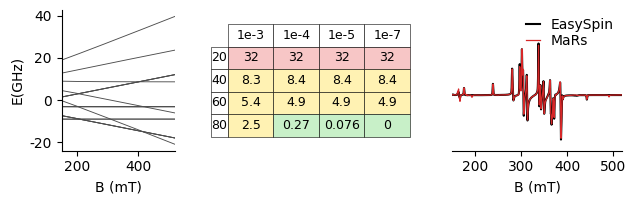

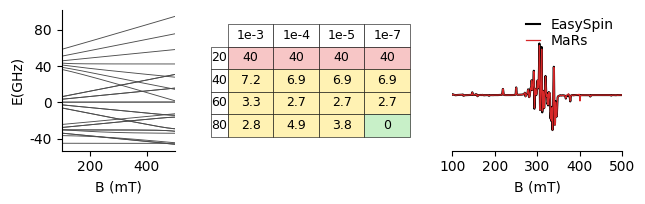

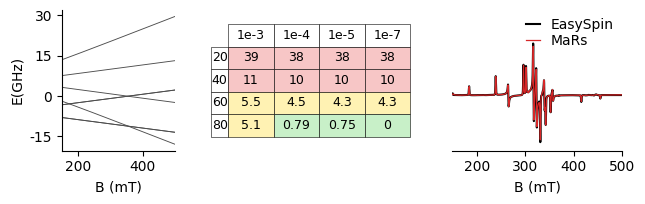

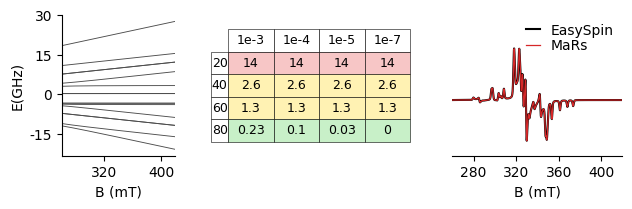

In [3]:
from plot_examples import load_mars, plot_example

for k in range(1, 5):
    spectra, fields = load_mars(k)
    sample, _, _ = examples.EXAMPLES[k](80, 1e-7, THRESHOLD, save_path=None)
    plot_example(k, sample, spectra, fields)